# Regresión Lineal con una Variable

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Vamos a construir, paso a paso, un modelo que predice el **precio de una vivienda** a partir de su **área** (pies cuadrados). Es el ejemplo clásico del curso (precios de casas en Monroe, Nueva Jersey, EE.UU.).

## 1. ¿Qué vamos a hacer?

El precio de una casa se puede escribir como una **línea recta**:

$$\text{precio} = m \cdot (\text{área}) + b$$

donde **m** es la pendiente (cuánto sube el precio por cada pie cuadrado) y **b** es el intercepto (el punto de partida). El modelo *aprende* los valores de m y b a partir de los datos.

Importamos las librerías: **pandas** (tablas), **numpy** (cálculo), **matplotlib** (gráficas) y la **regresión lineal** de scikit-learn.

In [1]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt

Cargamos los datos desde el repositorio (área y precio de 5 casas). Así corre en Colab sin subir nada.

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/homeprices.csv')
df

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


Graficamos los puntos (área vs precio) para ver si tienen forma de línea. Se ve una relación claramente lineal.

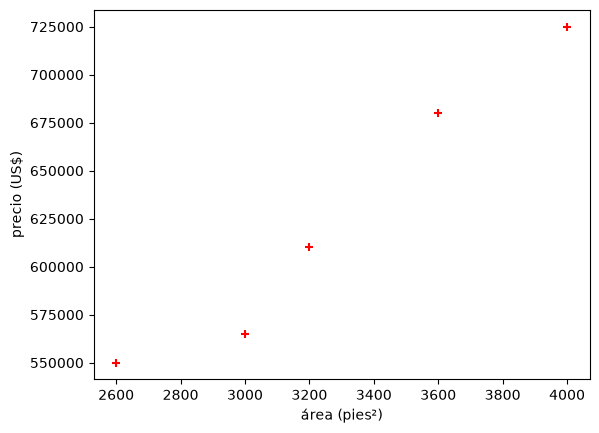

In [3]:
plt.xlabel('área (pies²)')
plt.ylabel('precio (US$)')
plt.scatter(df.area, df.price, color='red', marker='+')
plt.show()

Separamos las **variables**: `X` es la entrada (el área) y `y` es lo que queremos predecir (el precio).

In [4]:
X = df.drop('price', axis='columns')
X

,area
0,2600
1,3000
2,3200
3,3600
4,4000


In [5]:
y = df.price
y

0    550000
1    565000
2    610000
3    680000
4    725000
Name: price, dtype: int64

Creamos el objeto de regresión lineal y lo **entrenamos** con `.fit(X, y)`. Aquí el modelo aprende m y b.

In [6]:
# Crear el objeto de regresión lineal
reg = linear_model.LinearRegression()
reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[135.79]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.806e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


**(1) Predecir el precio de una casa de 3300 pies²**

In [7]:
reg.predict([[3300]])

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([628715.75342466])

Vemos la pendiente **m** (`coef_`) y el intercepto **b** (`intercept_`) que aprendió el modelo.

In [8]:
reg.coef_

array([135.78767123])

In [9]:
reg.intercept_

np.float64(180616.43835616432)

Comprobamos la fórmula a mano: **Y = m · X + b**. Debe dar el mismo valor que la predicción anterior.

In [10]:
3300 * reg.coef_[0] + reg.intercept_

np.float64(628715.7534246575)

**(2) Predecir el precio de una casa de 5000 pies²**

In [11]:
reg.predict([[5000]])

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([859554.79452055])

Dibujamos la **recta de regresión** (línea azul) sobre los puntos reales (rojo). Así vemos cómo el modelo ajusta los datos.

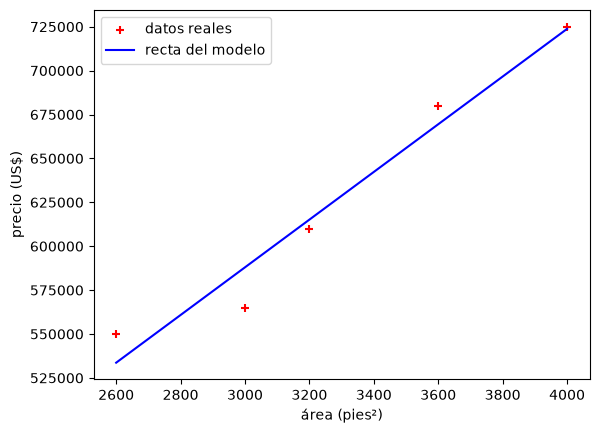

In [12]:
plt.xlabel('área (pies²)')
plt.ylabel('precio (US$)')
plt.scatter(df.area, df.price, color='red', marker='+', label='datos reales')
plt.plot(df.area, reg.predict(df[['area']]), color='blue', label='recta del modelo')
plt.legend()
plt.show()

## 2. Predecir una lista completa de áreas

Cargamos un archivo `areas.csv` con muchas áreas y predecimos el precio de todas de una sola vez.

In [13]:
area_df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/areas.csv')
area_df.head(3)

,area
0,1000
1,1500
2,2300


In [14]:
p = reg.predict(area_df)
p

array([ 316404.10958904,  384297.94520548,  492928.08219178,
        661304.79452055,  740061.64383562,  799808.21917808,
        926090.75342466,  650441.78082192,  825607.87671233,
        492928.08219178, 1402705.47945205, 1348390.4109589 ,
       1144708.90410959])

Agregamos la columna de precios predichos a la tabla.

In [15]:
area_df['prices'] = p
area_df

,area,prices
0,1000,3.164041e+05
1,1500,3.842979e+05
2,2300,4.929281e+05
3,3540,6.613048e+05
4,4120,7.400616e+05
5,4560,7.998082e+05
6,5490,9.260908e+05
7,3460,6.504418e+05
8,4750,8.256079e+05
9,2300,4.929281e+05


## Ejercicio práctico

**Enunciado (del curso):** Predecir el **ingreso per cápita de Canadá en el año 2020**. Construir un modelo de regresión y predecir el ingreso per cápita de los ciudadanos canadienses para 2020.

Lo resolvemos paso a paso.

**Paso 1.** Cargamos los datos históricos (año → ingreso per cápita en US$).

In [16]:
df_can = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/canada_per_capita_income.csv')
df_can.head()

,year,per capita income (US$)
0,1970,3399.299037
1,1971,3768.297935
2,1972,4251.175484
3,1973,4804.463248
4,1974,5576.514583


**Paso 2.** Renombramos la columna para que sea más fácil de usar y graficamos los datos.

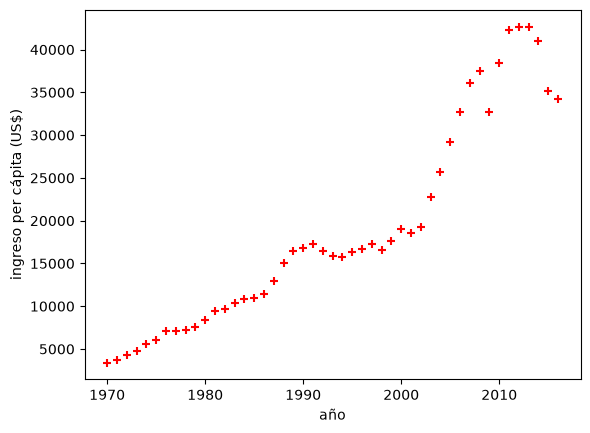

In [17]:
df_can.columns = ['year', 'income']
plt.xlabel('año')
plt.ylabel('ingreso per cápita (US$)')
plt.scatter(df_can.year, df_can.income, color='red', marker='+')
plt.show()

**Paso 3.** Entrenamos la regresión lineal: el año predice el ingreso.

In [18]:
reg_can = linear_model.LinearRegression()
reg_can.fit(df_can[['year']], df_can.income)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[828.47]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.632e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


**Paso 4.** Predecimos el ingreso per cápita para el año **2020**.

In [19]:
pred_2020 = reg_can.predict([[2020]])
pred_2020

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([41288.69409442])

**Paso 5.** Visualizamos la recta del modelo junto con los datos y marcamos la predicción de 2020.

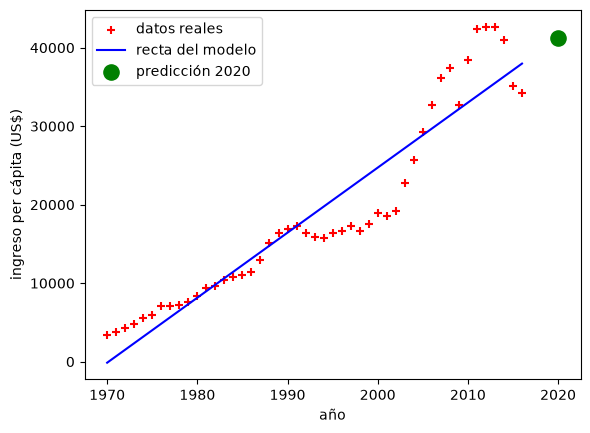

In [20]:
plt.xlabel('año')
plt.ylabel('ingreso per cápita (US$)')
plt.scatter(df_can.year, df_can.income, color='red', marker='+', label='datos reales')
plt.plot(df_can.year, reg_can.predict(df_can[['year']]), color='blue', label='recta del modelo')
plt.scatter([2020], pred_2020, color='green', s=120, label='predicción 2020')
plt.legend()
plt.show()

In [21]:
print(f"Ingreso per cápita estimado de Canadá en 2020: US$ {pred_2020[0]:,.2f}")

Ingreso per cápita estimado de Canadá en 2020: US$ 41,288.69


**Conclusión:** el modelo estima un ingreso per cápita de aproximadamente **US$ 41,289** para 2020. La relación año-ingreso es fuertemente lineal, por lo que la regresión lineal es adecuada para este problema.